# 05 - Currency and FX conversions

**Question:** how does the generator choose the payment currency, and what decides `currency_conversion_count`?

Works on the `feat` view through `src/eda.py`, **normal payments only** (anomalies are in `02_anomaly_types`). Charts are saved with the prefix `C`.

**Home currency of a country** = the currency used most often by senders whose bank is in that country. It is derived from the data, then checked against the official ISO 4217 currency (external reference, allowed by the rules for checking only).

## 0. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether Jupyter was started in the project root or in notebooks/
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
assert (ROOT / "src").exists(), f"Project root not found from {Path.cwd()}"
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import eda

eda.connect()  # in-memory DuckDB in UTC with views tx (clean) and feat (clean + features). If RAM runs out: eda.connect(memory_limit="3GB")
eda.require_columns("feat", ["sender_country", "receiver_country", "party_pair", "is_domestic"])
q, save = eda.q, eda.save

# Normal payments only: the rules in this notebook describe regular traffic (anomalies are in 02_anomaly_types)
eda.con.execute("CREATE OR REPLACE VIEW normal AS SELECT * FROM feat WHERE is_anomaly = 0")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

tx     10,000,000 rows x 21 columns
feat   10,000,000 rows x 40 columns
DuckDB 2.0.0 | time zone UTC


## 1. Sanity check

In [2]:
checks = q("""
    SELECT count(*)                                AS rows,
           count(*) FILTER (WHERE is_anomaly = 0)  AS normal_rows,
           min(epoch_seconds)                      AS first_payment,
           max(epoch_seconds)                      AS last_payment
    FROM feat
""")
assert checks.loc[0, "rows"] == 10_000_000
assert checks.loc[0, "normal_rows"] == 9_992_994
checks

,rows,normal_rows,first_payment,last_payment
0,10000000,9992994,2023-04-30 11:22:26+00:00,2023-07-31 09:56:01+00:00


## Hypotheses (written before testing)

| ID | Hypothesis | Test |
|---|---|---|
| H-C1 | Every country has one home currency, and most payments are made in the sender's home currency | Home currency per sender country, its share, and a check against ISO 4217 (C1) |
| H-C2 | The currency choice depends on who pays whom (party types) or on whether both sides share a currency | Currency source by party pair and by same / different home currency (C2) |
| H-C3 | The currency comes from the banks on the actual route (bank path), not from the BIC columns | Currency vs the home currency of the first, last and middle path banks; the rows where `ordering_bic8` and the first path bank disagree (C3) |
| H-C4 | `currency_conversion_count` = the number of times the home currency changes between consecutive banks on the path | Predicted vs actual count on every row (C4) |
| H-C5 | The payment currency itself adds or removes conversions | Conversions on routes whose banks all share one currency, by payment currency (C5) |

## C1. Home currency of each country (H-C1)

In [3]:
eda.con.execute("""
    CREATE OR REPLACE TEMP TABLE home AS
    SELECT sender_country AS country,
           arg_max(currency_code, n)  AS home_currency,
           max(n) / sum(n)            AS home_share,
           sum(n)                     AS payments_sent
    FROM (SELECT sender_country, currency_code, count(*) AS n FROM normal GROUP BY 1, 2)
    GROUP BY 1
""")
c1 = q("SELECT * FROM home ORDER BY payments_sent DESC")
total = c1.payments_sent.sum()
print(f"Countries with sending banks: {len(c1)}")
print(f"Payments in the sender country's home currency: {(c1.home_share * c1.payments_sent).sum() / total * 100:.1f}%")
print(f"Home share per country: min {c1.home_share.min():.3f} ({c1.loc[c1.home_share.idxmin(), 'country']}), "
      f"median {c1.home_share.median():.3f}, max {c1.home_share.max():.3f}")

Countries with sending banks: 228
Payments in the sender country's home currency: 89.4%
Home share per country: min 0.693 (RU), median 0.872, max 1.000


In [4]:
# Check against the official ISO 4217 currency of the 20 largest sending countries (reference: ISO 4217 / SIX Group)
ISO_4217 = {"US": "USD", "CH": "CHF", "GB": "GBP", "FR": "EUR", "DE": "EUR", "SG": "SGD", "CN": "CNY", "IT": "EUR",
            "BE": "EUR", "LU": "EUR", "NL": "EUR", "HK": "HKD", "JP": "JPY", "AU": "AUD", "IM": "GBP", "FI": "EUR",
            "ES": "EUR", "CA": "CAD", "KR": "KRW", "AT": "EUR"}
top20 = c1.head(20).assign(official_currency=lambda d: d.country.map(ISO_4217))
top20["matches"] = top20.home_currency == top20.official_currency
print(f"Derived home currency = official currency for {top20.matches.sum()} of 20 countries")
top20.round(3)

Derived home currency = official currency for 20 of 20 countries


,country,home_currency,home_share,payments_sent,official_currency,matches
0,US,USD,0.905,1581563.0,USD,True
1,CH,CHF,0.888,785903.0,CHF,True
2,GB,GBP,0.886,662252.0,GBP,True
3,FR,EUR,0.940,538477.0,EUR,True
4,DE,EUR,0.945,509096.0,EUR,True
5,SG,SGD,0.875,392987.0,SGD,True
6,CN,CNY,0.862,341599.0,CNY,True
7,IT,EUR,0.933,298435.0,EUR,True
8,BE,EUR,0.935,295799.0,EUR,True
9,LU,EUR,0.937,289965.0,EUR,True


In [5]:
# Countries that receive payments but never send any: their home currency cannot be derived from senders
no_home = q("""
    SELECT receiver_country, count(*) AS payments_received
    FROM normal
    WHERE receiver_country NOT IN (SELECT country FROM home)
    GROUP BY 1
""")
no_home

,receiver_country,payments_received
0,ER,1


## C2. Does the currency depend on who pays whom? (H-C2)
Currency source using the BIC columns: the sender's home currency, else the receiver's, else USD, else EUR, else any other currency.

In [6]:
c2 = q("""
    WITH c AS (
        SELECT n.party_pair, n.currency_code AS cur, hs.home_currency AS sender_home, hr.home_currency AS receiver_home
        FROM normal n
        JOIN home hs ON hs.country = n.sender_country
        LEFT JOIN home hr ON hr.country = n.receiver_country
    )
    SELECT party_pair,
           sender_home = receiver_home                                   AS same_home_currency,
           count(*)                                                      AS n,
           100 * avg((cur = sender_home)::INT)                           AS pct_sender_home,
           100 * avg((cur <> sender_home AND cur = receiver_home)::INT)  AS pct_receiver_home,
           100 * avg((cur NOT IN (sender_home, coalesce(receiver_home, '')) AND cur = 'USD')::INT) AS pct_usd,
           100 * avg((cur NOT IN (sender_home, coalesce(receiver_home, '')) AND cur = 'EUR')::INT) AS pct_eur,
           100 * avg((cur NOT IN (sender_home, coalesce(receiver_home, ''), 'USD', 'EUR'))::INT) AS pct_other
    FROM c
    WHERE receiver_home IS NOT NULL
    GROUP BY 1, 2
    ORDER BY 2, 1
""")
c2.round(1)

,party_pair,same_home_currency,n,pct_sender_home,pct_receiver_home,pct_usd,pct_eur,pct_other
0,B2B,False,1907676,88.4,5.2,1.2,2.2,3.0
1,B2C,False,4748498,88.6,5.0,1.3,2.3,2.9
2,C2B,False,512881,88.4,5.2,1.3,2.2,3.0
3,C2C,False,1274677,88.7,4.9,1.3,2.2,3.0
4,B2B,True,362209,94.6,0.0,1.2,1.5,2.8
5,B2C,True,852466,94.4,0.0,1.3,1.6,2.8
6,C2B,True,96881,94.8,0.0,1.3,1.4,2.6
7,C2C,True,237705,94.5,0.0,1.3,1.6,2.7


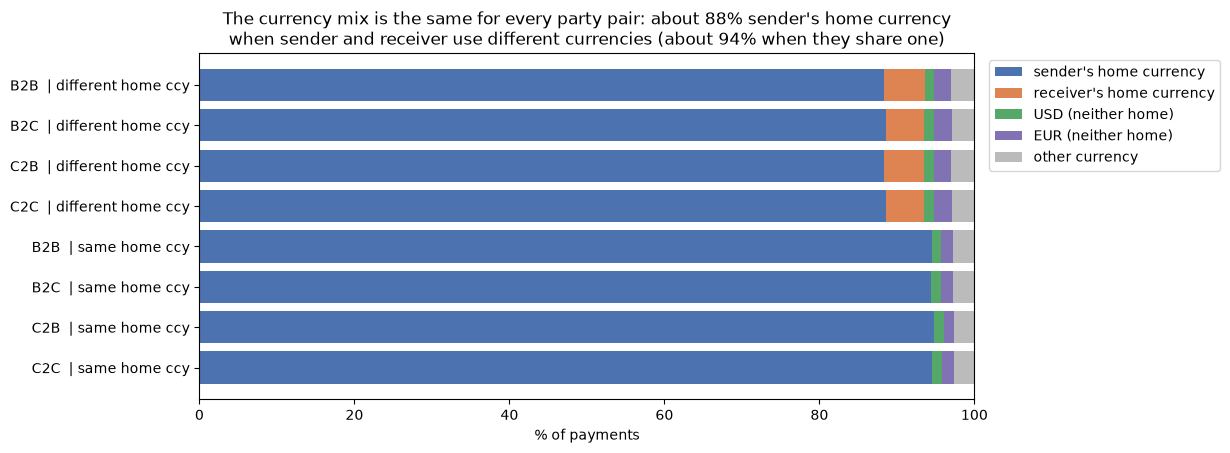

In [7]:
cols = ["pct_sender_home", "pct_receiver_home", "pct_usd", "pct_eur", "pct_other"]
labels = ["sender's home currency", "receiver's home currency", "USD (neither home)", "EUR (neither home)", "other currency"]
colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B3", "#BBBBBB"]
d = c2.assign(group=c2.party_pair + np.where(c2.same_home_currency, "  | same home ccy", "  | different home ccy")).set_index("group")[cols]
fig, ax = plt.subplots(figsize=(10, 4.5))
left = np.zeros(len(d))
for c, l, col in zip(cols, labels, colors):
    ax.barh(d.index, d[c], left=left, color=col, label=l)
    left += d[c].to_numpy()
ax.set_xlim(0, 100)
ax.invert_yaxis()
ax.set_xlabel("% of payments")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
ax.set_title("The currency mix is the same for every party pair: about 88% sender's home currency\n"
             "when sender and receiver use different currencies (about 94% when they share one)")
save(fig, "C2_currency_by_party_pair")
plt.show()

## C3. The currency comes from the banks on the route (H-C3)
Each path bank gets the home currency of its country (characters 5-6 of its BIC). Gaps (`...`) are skipped. The payment currency is then matched with the first bank, the last bank, a middle bank, or none of them.

In [8]:
eda.con.execute("""
    CREATE OR REPLACE TEMP TABLE path_homes AS
    WITH m AS (SELECT map_from_entries(list((country, home_currency))) AS hm FROM home)
    SELECT n.currency_code AS cur,
           n.currency_conversion_count AS conversions,
           n.participant_count AS banks,
           n.path_gaps > 0 AS has_gap,
           hs.home_currency AS ordering_bic_home,
           list_transform(list_filter(string_split(n.bic8_path, ';'), lambda x: x <> '...'),
                          lambda b: m.hm[substr(b, 5, 2)]) AS homes
    FROM normal n
    CROSS JOIN m
    JOIN home hs ON hs.country = n.sender_country
""")
c3 = q("""
    SELECT least(banks, 5) AS banks,
           count(*) AS n,
           100 * avg((cur = homes[1])::INT)                                                   AS pct_first_bank,
           100 * avg((cur <> homes[1] AND cur = homes[-1])::INT)                             AS pct_last_bank,
           100 * avg((cur <> homes[1] AND cur <> homes[-1] AND list_contains(homes, cur))::INT) AS pct_middle_bank,
           100 * avg((NOT list_contains(homes, cur))::INT)                                    AS pct_off_path
    FROM path_homes
    GROUP BY 1 ORDER BY 1
""")
c3_all = q("""
    SELECT 100 * avg((cur = homes[1])::INT)                                                   AS pct_first_bank,
           100 * avg((cur <> homes[1] AND cur = homes[-1])::INT)                             AS pct_last_bank,
           100 * avg((cur <> homes[1] AND cur <> homes[-1] AND list_contains(homes, cur))::INT) AS pct_middle_bank,
           100 * avg((NOT list_contains(homes, cur))::INT)                                    AS pct_off_path
    FROM path_homes
""")
display(c3_all.round(2))
c3.round(2)  # banks: 5 = 5 or more

,pct_first_bank,pct_last_bank,pct_middle_bank,pct_off_path
0,93.42,3.8,1.52,1.27


,banks,n,pct_first_bank,pct_last_bank,pct_middle_bank,pct_off_path
0,2,6318885,94.73,3.84,0.00,1.43
1,3,2322649,92.13,3.75,3.00,1.11
2,4,854759,90.21,3.71,5.21,0.88
3,5,496701,88.16,3.67,7.53,0.65


In [9]:
# Decisive test: rows where the ordering BIC and the first path bank have DIFFERENT home currencies
c3_test = q("""
    SELECT ordering_bic_home = homes[1]            AS same_home_currency,
           count(*)                               AS n,
           100 * avg((cur = ordering_bic_home)::INT) AS pct_currency_is_ordering_bic_home,
           100 * avg((cur = homes[1])::INT)          AS pct_currency_is_first_path_bank_home
    FROM path_homes
    GROUP BY 1 ORDER BY 1
""")
c3_test.round(1)

,same_home_currency,n,pct_currency_is_ordering_bic_home,pct_currency_is_first_path_bank_home
0,False,433526,1.6,93.1
1,True,9559468,93.4,93.4


In [10]:
off = q("""
    SELECT cur, count(*) AS n FROM path_homes WHERE NOT list_contains(homes, cur)
    GROUP BY 1 ORDER BY n DESC LIMIT 6
""")
off["pct_of_off_path"] = (off.n / q("SELECT count(*) AS n FROM path_homes WHERE NOT list_contains(homes, cur)").loc[0, "n"] * 100).round(1)
off  # currencies used although no bank on the route has them as home currency

,cur,n,pct_of_off_path
0,EUR,58046,45.8
1,USD,40368,31.9
2,GBP,2361,1.9
3,CNY,2169,1.7
4,CHF,1354,1.1
5,JPY,1329,1.0


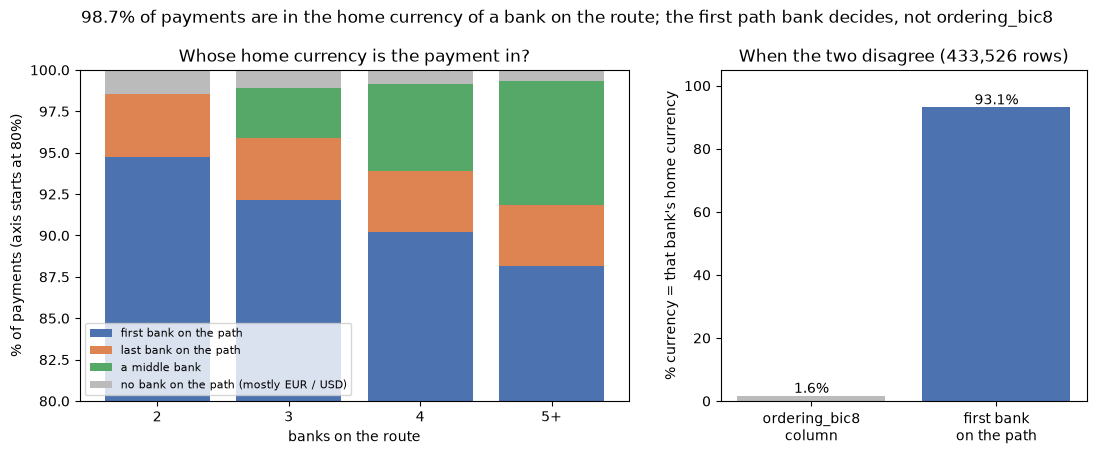

In [11]:
cols = ["pct_first_bank", "pct_last_bank", "pct_middle_bank", "pct_off_path"]
labels = ["first bank on the path", "last bank on the path", "a middle bank", "no bank on the path (mostly EUR / USD)"]
colors = ["#4C72B0", "#DD8452", "#55A868", "#BBBBBB"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), gridspec_kw={"width_ratios": [3, 2]})
d = c3.set_index("banks")[cols]
bottom = np.zeros(len(d))
for c, l, col in zip(cols, labels, colors):
    axes[0].bar(d.index.astype(str), d[c], bottom=bottom, color=col, label=l)
    bottom += d[c].to_numpy()
axes[0].set_ylim(80, 100)
axes[0].set_xticks(range(len(d)))
axes[0].set_xticklabels(["2", "3", "4", "5+"])
axes[0].set_xlabel("banks on the route")
axes[0].set_ylabel("% of payments (axis starts at 80%)")
axes[0].legend(loc="lower left", fontsize=8)
axes[0].set_title("Whose home currency is the payment in?")
t = c3_test.set_index("same_home_currency").loc[False]
axes[1].bar(["ordering_bic8\ncolumn", "first bank\non the path"],
            [t.pct_currency_is_ordering_bic_home, t.pct_currency_is_first_path_bank_home], color=["#BBBBBB", "#4C72B0"])
for i, v in enumerate([t.pct_currency_is_ordering_bic_home, t.pct_currency_is_first_path_bank_home]):
    axes[1].text(i, v + 1, f"{v:.1f}%", ha="center")
axes[1].set_ylim(0, 105)
axes[1].set_ylabel("% currency = that bank's home currency")
axes[1].set_title(f"When the two disagree ({int(t.n):,} rows)")
fig.suptitle(f"{100 - c3_all.pct_off_path[0]:.1f}% of payments are in the home currency of a bank on the route; "
             f"the first path bank decides, not ordering_bic8", y=1.02)
save(fig, "C3_currency_from_route")
plt.show()

## C4. The conversion-count rule (H-C4)
Predicted conversions = number of consecutive path banks whose home currencies differ. Example: banks in FR → US → GB have homes EUR → USD → GBP, so 2 conversions.

In [12]:
eda.con.execute("""
    CREATE OR REPLACE TEMP TABLE conv AS
    SELECT *, len(list_filter(list_zip(homes[1:-2], homes[2:]), lambda p: p[1] <> p[2])) AS predicted,
           len(list_filter(homes, lambda h: h IS NULL)) > 0 AS has_unknown_home
    FROM path_homes
""")
c4 = q("""
    SELECT has_gap, count(*) AS n,
           sum((conversions = predicted)::INT) AS exact_matches,
           100 * avg((conversions = predicted)::INT) AS pct_exact
    FROM conv GROUP BY 1 ORDER BY 1
""")
display(c4)
q("SELECT cur, conversions, predicted, homes FROM conv WHERE conversions <> predicted")  # the exceptions

,has_gap,n,exact_matches,pct_exact
0,False,9226331,9226330.0,99.999989
1,True,766663,766663.0,100.000000


,cur,conversions,predicted,homes
0,EUR,1,0,"[EUR, None]"


In [13]:
# The only bank country without a derived home currency is Eritrea (ER, never sends). Official currency: ERN (ISO 4217).
fixed = q("""
    SELECT count(*) AS n,
           sum((conversions = len(list_filter(list_zip(list_transform(homes, lambda h: coalesce(h, 'ERN'))[1:-2],
                                                         list_transform(homes, lambda h: coalesce(h, 'ERN'))[2:]),
                                                lambda p: p[1] <> p[2])))::INT) AS exact_matches
    FROM conv
""")
fixed["pct_exact"] = fixed.exact_matches / fixed.n * 100
fixed

,n,exact_matches,pct_exact
0,9992994,9992994.0,100.0


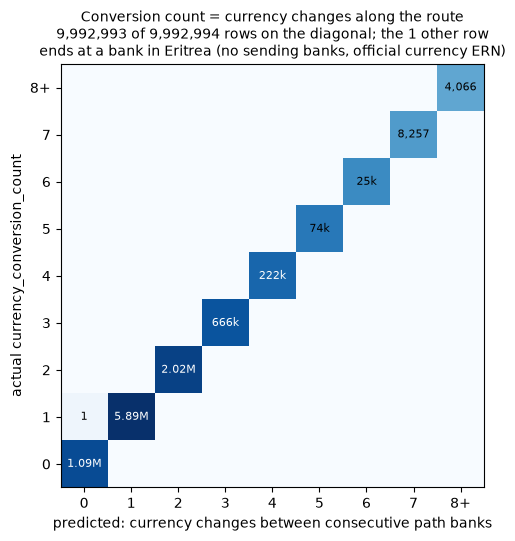

In [14]:
c4_mat = q("""
    SELECT least(predicted, 8) AS predicted, least(conversions, 8) AS actual, count(*) AS n
    FROM conv GROUP BY 1, 2
""").pivot(index="actual", columns="predicted", values="n").fillna(0)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(np.log10(c4_mat.to_numpy() + 1), cmap="Blues", origin="lower")
for (i, j), v in np.ndenumerate(c4_mat.to_numpy()):
    if v > 0:
        label = f"{v / 1e6:.2f}M" if v >= 1e6 else f"{v / 1e3:.0f}k" if v >= 1e4 else f"{int(v):,}"
        ax.text(j, i, label, ha="center", va="center", fontsize=8, color="black" if v < 1e5 else "white")
ax.set_xticks(range(c4_mat.shape[1]))
ax.set_xticklabels([str(int(c)) if c < 8 else "8+" for c in c4_mat.columns])
ax.set_yticks(range(c4_mat.shape[0]))
ax.set_yticklabels([str(int(r)) if r < 8 else "8+" for r in c4_mat.index])
ax.set_xlabel("predicted: currency changes between consecutive path banks")
ax.set_ylabel("actual currency_conversion_count")
ax.set_title(f"Conversion count = currency changes along the route\n"
             f"{int(c4.exact_matches.sum()):,} of {int(c4.n.sum()):,} rows on the diagonal; the 1 other row\n"
             f"ends at a bank in Eritrea (no sending banks, official currency ERN)", fontsize=10)
save(fig, "C4_conversion_rule")
plt.show()

## C5. Does the payment currency add conversions? (H-C5)
Routes where every bank has the same home currency, split by whether the payment is made in that currency or in another one.

In [15]:
c5 = q("""
    SELECT cur = homes[1] AS paid_in_the_route_currency,
           count(*) AS n,
           avg(conversions) AS avg_conversions,
           max(conversions) AS max_conversions
    FROM conv
    WHERE len(list_distinct(homes)) = 1 AND NOT has_unknown_home
    GROUP BY 1 ORDER BY 1
""")
c5

,paid_in_the_route_currency,n,avg_conversions,max_conversions
0,False,13440,0.0,0
1,True,1072652,0.0,0


## C6. Results → rules (verified on all 9,992,994 normal payments)

| ID | Rule (condition → effect → size → rows covered) | Evidence | Confidence |
|---|---|---|---|
| R-C1 | Every bank country has **one home currency**: the most used currency of its senders accounts for a median **87.2%** of that country's payments (lowest: Russia 69.3%). The derived home currency equals the official ISO 4217 currency for **20 of the 20** largest sending countries. Overall **89.4%** of payments are in the home currency of the `ordering_bic8` country. | C1 | High |
| R-C2 | The currency choice **does not depend on party types**: for all four party pairs, when sender and receiver use different home currencies the mix is **88.4-88.7%** sender's home, **4.9-5.2%** receiver's home, **1.2-1.3%** USD, **2.2-2.3%** EUR and **2.9-3.0%** other; when they share one, **94.4-94.8%** is in that shared currency. | C2 | High |
| R-C3 | The currency is taken from the **banks on the actual route**: **98.7%** of payments are in the home currency of a bank on `bic8_path`: the **first** path bank **93.4%**, the **last** **3.8%**, a **middle** bank **1.5%**; only **1.3%** use a currency of no bank on the route (EUR 45.8% and USD 31.9% of these). Each extra middle bank moves about 1.9-2.6 points from the first bank to the middle banks (first bank 94.7% → 92.1% → 90.2% → 88.2% for 2, 3, 4, 5+ banks). In the **433,526** rows where `ordering_bic8` and the first path bank have different home currencies, the currency follows the **first path bank in 93.1%** and `ordering_bic8` in only **1.6%**. | C3 | High |
| R-C4 | `currency_conversion_count` = **the number of consecutive path banks whose home currencies differ** (gaps `...` skipped). Exact on **9,992,993 of 9,992,994** rows, including all **766,663** routes with gaps. The single exception ends at a bank in **Eritrea**, which never sends, so its home currency cannot be derived; with its official currency **ERN**, the rule is exact on **100%** of rows. | C4 | High (deterministic rule) |
| R-C5 | The **payment currency never adds a conversion**: all **1,086,092** routes whose banks share one home currency have **0** conversions, including the **13,440** payments made in a different currency. | C5 | High |

**Hypotheses that did not hold:**
- H-C2 "the currency depends on who pays whom": rejected, the mix is identical for all party pairs (within 0.4 points).
- H-C3, BIC-column version: `ordering_bic8` does **not** decide the currency (1.6% when it disagrees with the route). The route does. This matches the 5% endpoint noise found in `02_anomaly_types` (A6) and suggests `ordering_bic8` is a re-labelled copy of the first path bank.
- H-C5 "the payment currency adds conversions": rejected (0 conversions on single-currency routes even when paying in another currency).

**Still unexplained / limits:** why the home-currency share varies by country (69%-100%), and the exact probabilities used to pick the last or a middle bank's currency. Eritrea's home currency (ERN) is the only value taken from outside the data (ISO 4217), and it affects one row.